**Name**: Shayan Salehi

**Student ID** 404203509

## Shape Moments

In this section, we will utilize Shape Moments to detect and count pills in a photo. You are free to use any tool from the NumPy and OpenCV packages, except for the shape moment function, which you must implement manually.

In [ ]:
!pip install opencv-python numpy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Mask Extraction
You are free to use any tools in this section. Your inputs should be the image path and any hyperparameters needed for mask creation.

In [1]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from typing import Any
def create_mask(image_path: str, **kwargs: Any) -> np.ndarray:

    ###### TODO ######
    hue_tol = kwargs.get('hue_tolerance', 255)
    sat_tol = kwargs.get('sat_tolerance', 15)
    val_tol = kwargs.get('val_tolerance', 15)

    img = cv2.imread(image_path)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.int16)
    h, w = hsv.shape[:2]

    border_width = 8
    border = np.concatenate([
        hsv[:border_width, :, :].reshape(-1, 3),
        hsv[-border_width:, :, :].reshape(-1, 3),
        hsv[:, :border_width, :].reshape(-1, 3),
        hsv[:, -border_width:, :].reshape(-1, 3),
    ], axis=0)
    bg = np.median(border, axis=0)

    dh = np.abs(hsv[:, :, 0] - bg[0])
    dh = np.minimum(dh, 180 - dh)
    ds = np.abs(hsv[:, :, 1] - bg[1])
    dv = np.abs(hsv[:, :, 2] - bg[2])

    fg_mask = ((dh > hue_tol) | (ds > sat_tol) | (dv > val_tol))
    fg_mask = (fg_mask.astype(np.uint8)) * 255

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    fg_mask = cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    fg_mask = cv2.morphologyEx(fg_mask, cv2.MORPH_OPEN, kernel, iterations=1)
    ##################
    return fg_mask

## Shape Moments
Implement the shape moment function. You can use the following formula for your implementation. This is the closed-form formula for moment generation utilizing Green's theorem.

$$m_{pq} = \frac{1}{(p+q+1)(p+q+2)} \sum_{i=0}^{N-1} (x_i y_{i+1} - x_{i+1} y_i) \sum_{k=0}^{p} \sum_{l=0}^{q} \frac{\binom{p}{k} \binom{q}{l}}{\binom{p+q}{k+l}} x_i^{p-k} x_{i+1}^k y_i^{q-l} y_{i+1}^l$$

Note: You don't need to implement the formula, just use it for calculating the values needed for your task.

In [2]:
import numpy as np
import math

def calculate_manual_moments(contour: np.ndarray) -> dict[str,float]:
    """
    Manually calculates moments for a contour using Green's Theorem.
    """
    ###### TODO ######
    keys = ['m00', 'm10', 'm01', 'm20', 'm11', 'm02', 'mu20', 'mu11', 'mu02']
    pts = np.asarray(contour, dtype=np.float64).reshape(-1, 2)
    if pts.shape[0] < 3:
        return {k: 0.0 for k in keys}

    x = pts[:, 0]
    y = pts[:, 1]
    x_next = np.roll(x, -1)
    y_next = np.roll(y, -1)

    cross = x * y_next - x_next * y

    m00 = cross.sum() / 2.0
    m10 = ((x + x_next) * cross).sum() / 6.0
    m01 = ((y + y_next) * cross).sum() / 6.0
    m20 = ((x * x + x * x_next + x_next * x_next) * cross).sum() / 12.0
    m02 = ((y * y + y * y_next + y_next * y_next) * cross).sum() / 12.0
    m11 = ((2.0 * x * y + x * y_next + x_next * y + 2.0 * x_next * y_next) * cross).sum() / 24.0

    if m00 < 0:
        m00, m10, m01, m20, m11, m02 = -m00, -m10, -m01, -m20, -m11, -m02

    if m00 < 1e-9:
        return {k: 0.0 for k in keys}

    cx = m10 / m00
    cy = m01 / m00
    mu20 = m20 - cx * m10
    mu02 = m02 - cy * m01
    mu11 = m11 - cx * m01

    moments = {
        'm00': m00, 'm10': m10, 'm01': m01,
        'm20': m20, 'm11': m11, 'm02': m02,
        'mu20': mu20, 'mu11': mu11, 'mu02': mu02,
    }
    ##################

    return moments

Use the moment function and the pill mask to detect the pills in the photo. Do not modify the function outside of the TODO section. Any conditions applied to the shapes must be directly related to their shape moments.


In [3]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from typing import Any
# Pass the original 'img' into the function so we have something to draw the results on
def count_pills_with_moment(pill_mask, img, **kwargs: Any):

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

    clean_thresh = cv2.morphologyEx(pill_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    _, clean_thresh = cv2.threshold(clean_thresh, 127, 255, cv2.THRESH_BINARY)

    contours, _ = cv2.findContours(clean_thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    valid_pill_count = 0

    # Draw your the selected contours on this image
    final_result_img = img.copy()


    for contour in contours:
        M = calculate_manual_moments(contour)
        perimeter = cv2.arcLength(contour, True)

        ###### TODO ######
        area = M['m00']
        if area < kwargs.get('min_area', 150.0):
            continue

        cx = M['m10'] / area
        cy = M['m01'] / area
        a = M['mu20'] / area
        b = M['mu11'] / area
        c = M['mu02'] / area

        common = (a + c) / 2.0
        delta = np.sqrt(max(0.0, ((a - c) / 2.0) ** 2 + b * b))
        lam1 = common + delta
        lam2 = common - delta
        if lam1 <= 1e-9:
            continue

        ratio = lam1 / lam2 if lam2 > 1e-9 else np.inf
        angle = abs(np.degrees(0.5 * np.arctan2(2.0 * b, a - c)))
        if angle > 90.0:
            angle = 180.0 - angle

        mode = kwargs.get('mode', 'all')
        circle_ratio = kwargs.get('circle_ratio', 1.8)
        oval_ratio = kwargs.get('oval_ratio', 1.8)
        angle_min = kwargs.get('angle_min', 12.0)
        angle_max = kwargs.get('angle_max', 60.0)

        if mode == 'circle':
            accept = ratio < circle_ratio
        elif mode == 'oval':
            accept = ratio >= oval_ratio
        elif mode == 'angled_oval':
            accept = (ratio >= oval_ratio) and (angle_min <= angle <= angle_max)
        else:
            accept = True

        if not accept:
            continue

        valid_pill_count += 1
        cv2.drawContours(final_result_img, [contour], -1, (0, 255, 0), 2)
        cv2.circle(final_result_img, (int(round(cx)), int(round(cy))), 5, (0, 0, 255), -1)
        ##################

    print(f"\n--- Final Output (Total pills counted: {valid_pill_count}) ---")
    cv2_imshow(final_result_img)



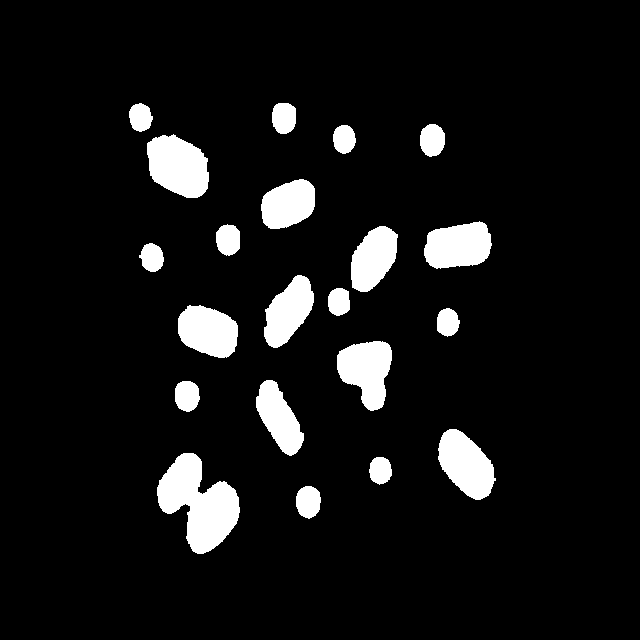

In [4]:
# Load your original image and create the mask
original_img = cv2.imread('pills-pink.jpg')

pill_mask = create_mask('pills-pink.jpg', hue_tolerance=255, sat_tolerance=15,val_tolerance=15)

cv2_imshow(pill_mask)


--- Final Output (Total pills counted: 21) ---


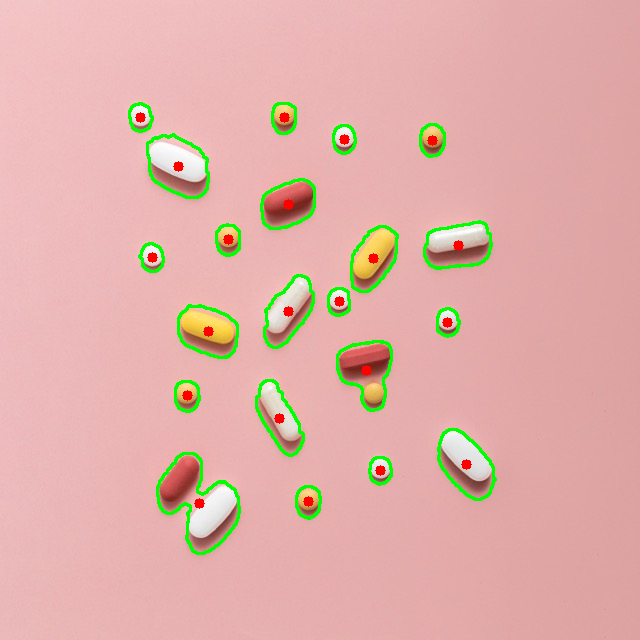

In [5]:
# Detect all shapes of pills
kwargs = {'mode': 'all'}
count_pills_with_moment(pill_mask, original_img, **kwargs)


--- Final Output (Total pills counted: 12) ---


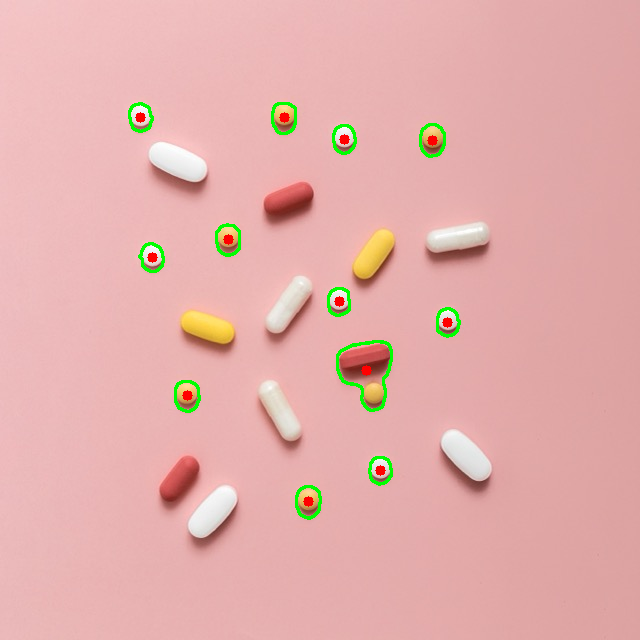

In [6]:
#Detect the circular pills
kwargs = {'mode': 'circle', 'circle_ratio': 1.8}
count_pills_with_moment(pill_mask, original_img, **kwargs)


--- Final Output (Total pills counted: 9) ---


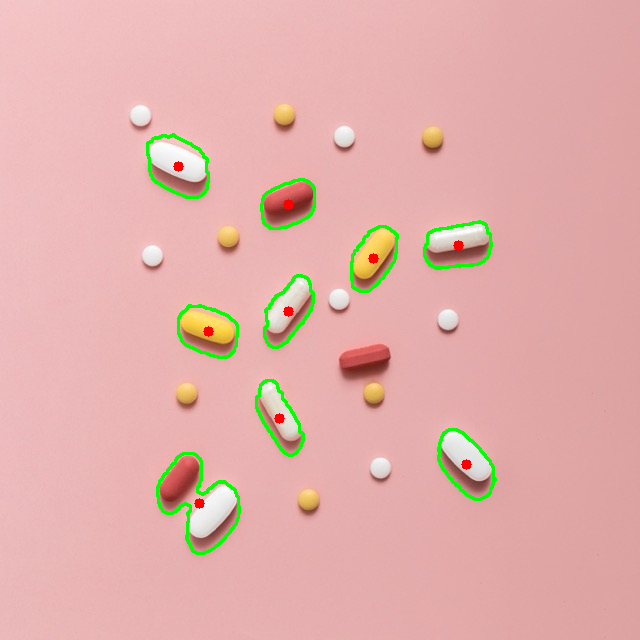

In [7]:
#Detect the oval shaped pills
kwargs = {'mode': 'oval', 'oval_ratio': 1.8}
count_pills_with_moment(pill_mask, original_img, **kwargs)


--- Final Output (Total pills counted: 5) ---


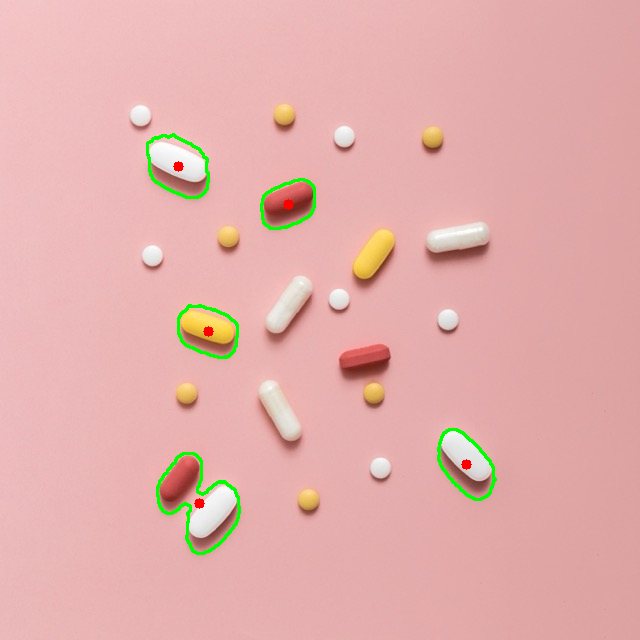

In [8]:
#Detect slightly angled oval shaped pills (Use the sample output as your refrence)
kwargs = {'mode': 'angled_oval', 'oval_ratio': 1.8, 'angle_min': 12.0, 'angle_max': 60.0}
count_pills_with_moment(pill_mask, original_img, **kwargs)

# Template Matching

The objective of this section is to locate specific tablets within an image using a manual Template Matching algorithm. By taking a small reference crop (the template) of a single pill, we will mathematically compare it across the entire image to find matching regions.

## Image Enhancment

A simple Image_Enhancer function to seperate the white tablets

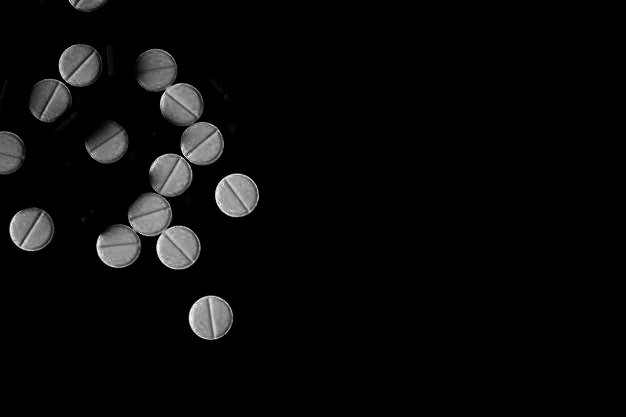

In [9]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
def Image_Enhancer(image_path:str) -> np.ndarray:
    image = cv2.imread(image_path)


    # 2. Run the feature extraction code
    ch2 = image[:, :, 2].astype(np.float64) # Red channel
    ch0 = image[:, :, 0].astype(np.float64) # Blue channel
    feature_extract = (ch0**6) * (ch2**2)

    max_val = np.max(feature_extract) + 1e-8
    enhanced_image = ((feature_extract / max_val) * 255).astype(np.uint8)

    cv2_imshow(enhanced_image)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

    return enhanced_image
enhanced_image = Image_Enhancer('pills-blue.jpg')

## Template Extraction

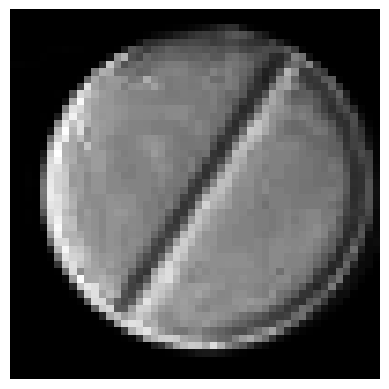

In [10]:
import matplotlib.pyplot as plt
tmp_size=50
tr_y=205
tr_x=5
template=enhanced_image[tr_y:tr_y+tmp_size,tr_x:tr_x+tmp_size]
plt.imshow(template,cmap='gray')
plt.axis('off')
plt.show()


## Template Matcher

Write a template matching algorithm. You are strictly limited to using NumPy for this task. Instead of extracting only the single best match, use a manually defined threshold to include all acceptable results. Ensure that no tablet is detected more than once.

The output is an empty image with the bounding boxes drawn on it.

In [11]:
import numpy as np

def template_matcher(img_array: np.ndarray, template: np.ndarray, threshold: float) -> np.ndarray:
    ###### TODO ######
    img = img_array.astype(np.float64)
    t = template.astype(np.float64)
    th, tw = t.shape[:2]
    H, W = img.shape[:2]
    out_h = H - th + 1
    out_w = W - tw + 1

    t_zero = t - t.mean()
    t_norm = np.sqrt((t_zero ** 2).sum()) + 1e-8

    eps = 1e-8
    score = np.full((out_h, out_w), -1.0, dtype=np.float64)
    for r in range(out_h):
        strip = img[r:r + th]
        windows = np.lib.stride_tricks.sliding_window_view(strip, (th, tw))[0]
        w_zero = windows - windows.mean(axis=(1, 2), keepdims=True)
        num = (w_zero * t_zero).sum(axis=(1, 2))
        den = np.sqrt((w_zero ** 2).sum(axis=(1, 2))) * t_norm + eps
        score[r] = num / den

    ys, xs = np.where(score >= threshold)
    order = np.argsort(-score[ys, xs])
    ys = ys[order]
    xs = xs[order]

    selected_points = []
    occupied = np.zeros((out_h, out_w), dtype=bool)
    for y, x in zip(ys, xs):
        if occupied[y, x]:
            continue
        selected_points.append((int(y), int(x)))
        y0 = max(0, y - th // 2)
        y1 = min(out_h, y + th // 2 + 1)
        x0 = max(0, x - tw // 2)
        x1 = min(out_w, x + tw // 2 + 1)
        occupied[y0:y1, x0:x1] = True

    boxed = np.zeros((H, W), dtype=np.uint8)
    for (y, x) in selected_points:
        y_bot = min(H - 1, y + th - 1)
        x_right = min(W - 1, x + tw - 1)
        boxed[y, x:x_right + 1] = 255
        boxed[y_bot, x:x_right + 1] = 255
        boxed[y:y_bot + 1, x] = 255
        boxed[y:y_bot + 1, x_right] = 255
    ##################
    print(f"Found {len(selected_points)} Tablets")
    return boxed

## Put Together

Found 13 Tablets


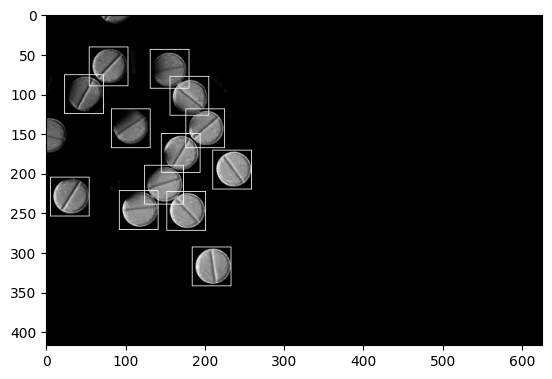

In [14]:
box=template_matcher(enhanced_image,template, threshold=0.4)

result=np.maximum(box,enhanced_image[:,:])
plt.imshow(result,cmap='gray')
plt.show()


# Conclusion
Test the shape moment algorithm on the blue pills image. Write a brief conclusion explaining which scenarios are best suited for each algorithm.

---

The shape moment method works poorly on `pills-blue.jpg`. This is because the white pills and the light background have very similar colors. The mask cannot separate them properly, leading to broken or merged shapes that confuse the algorithm.


Shape Moments: Best when objects have high contrast with the background and are easy to see. They are great for counting and identifying shapes (like circles vs. ovals) because they don't care if the object is rotated. However, they fail if the initial mask is bad.

Template Matching: Best when objects look identical but are hard to separate from the background using color. It looks for a specific pattern rather than a color mask. Its main weakness is that it fails if the objects are rotated or have different sizes than the template.

So we can use shape moments for clear, well-separated objects where geometry matters. Use template matching when colors are too similar but the objects all look the same.
